# 05 - Insight Bisnis (Fase 7)

## Setup

In [1]:
!pip install -q transformers accelerate statsmodels

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import gc
import hashlib
import json
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import torch
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportions_ztest
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()

FOLDER_PROJECT = Path('/content/drive/MyDrive/ulasan-ewallet')
FOLDER_PROCESSED = FOLDER_PROJECT / 'data' / 'processed'
FOLDER_GOLD = FOLDER_PROJECT / 'data' / 'gold'
FOLDER_MODEL = FOLDER_PROJECT / 'models'
FOLDER_HASIL_INDOBERT = FOLDER_PROCESSED / 'indobert'
FOLDER_APP_DATA = FOLDER_PROJECT / 'app' / 'data'
FOLDER_APP_DATA.mkdir(parents=True, exist_ok=True)
SEED = 42

ASPEK = ['transaksi', 'keamanan', 'akun', 'error_performa', 'cs', 'biaya_promo', 'paylater', 'kemudahan']
NAMA_ASPEK = {
    'transaksi': 'Transaksi', 'keamanan': 'Keamanan', 'akun': 'Akun', 'error_performa': 'Error/performa',
    'cs': 'CS', 'biaya_promo': 'Biaya/promo', 'paylater': 'Paylater', 'kemudahan': 'Kemudahan',
}
KELAS = ['neg', 'net', 'pos']
KOLOM_PRED = [f'pred_{a}' for a in ASPEK]

ulasan = pd.read_parquet(
    FOLDER_PROCESSED / 'ulasan_bersih.parquet',
    columns=['id_ulasan', 'aplikasi', 'rating', 'versi', 'tanggal', 'balasan', 'tanggal_balasan',
             'teks_ringan', 'jumlah_kata', 'bulan', 'hari_lonjakan'],
)
info_sentimen = json.loads((FOLDER_MODEL / 'indobert_sentimen' / 'info.json').read_text(encoding='utf-8'))
info_aspek = json.loads((FOLDER_MODEL / 'indobert_aspek' / 'info.json').read_text(encoding='utf-8'))
assert info_sentimen['versi_label'] == info_aspek['versi_label'], 'Model sentimen dan aspek dari versi label berbeda'
VERSI_LABEL = info_aspek['versi_label']
print(f"{len(ulasan):,} ulasan | sentimen: {info_sentimen['nama']} | aspek: {info_aspek['nama']} | versi label {VERSI_LABEL}")

398,742 ulasan | sentimen: Dua tahap (rating -> gold) | aspek: IndoBERT multi-label | versi label 6b6ec0d2


In [3]:
# Warna mengikuti aplikasi dan tidak pernah berubah (palet tervalidasi, 3 slot pertama aman untuk buta warna)
URUTAN_APLIKASI = ['dana', 'gopay', 'ovo']
NAMA = {'dana': 'DANA', 'gopay': 'GoPay', 'ovo': 'OVO'}
WARNA = {'dana': '#2a78d6', 'gopay': '#eb6834', 'ovo': '#1baf7a'}
PERMUKAAN = '#fcfcfb'
TINTA, TINTA_2, TINTA_REDUP, GARIS = '#0b0b0b', '#52514e', '#898781', '#c3c2b7'

plt.rcParams.update({
    'figure.figsize': (10, 4.5), 'figure.dpi': 110,
    'figure.facecolor': PERMUKAAN, 'axes.facecolor': PERMUKAAN,
    'font.family': 'sans-serif', 'font.size': 10,
    'axes.edgecolor': GARIS, 'axes.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.titlelocation': 'left', 'axes.titlecolor': TINTA,
    'axes.labelcolor': TINTA_2,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e1e0d9', 'grid.linewidth': 0.8,
    'xtick.color': GARIS, 'ytick.color': GARIS,
    'xtick.labelcolor': TINTA_REDUP, 'ytick.labelcolor': TINTA_REDUP,
    'lines.linewidth': 2, 'lines.markersize': 6,
    'legend.frameon': False, 'legend.labelcolor': TINTA_2,
})

## 7.1 Prediksi seluruh ulasan

In [6]:
PATH_PREDIKSI = FOLDER_PROCESSED / 'prediksi_ulasan.parquet'
PATH_INFO_PREDIKSI = FOLDER_PROCESSED / 'prediksi_ulasan_info.json'
info_prediksi = {'sentimen': info_sentimen['nama'], 'aspek': info_aspek['nama'], 'versi_label': VERSI_LABEL}
UKURAN_BAGIAN = 50_000  # checkpoint ke Drive setiap sekian ulasan
UKURAN_BATCH = 256

info_lama = json.loads(PATH_INFO_PREDIKSI.read_text(encoding='utf-8')) if PATH_INFO_PREDIKSI.exists() else {}
sudah_ada = PATH_PREDIKSI.exists() and {k: info_lama.get(k) for k in info_prediksi} == info_prediksi
if sudah_ada:
    print('Prediksi untuk model ini sudah ada di Drive; GPU tidak dibutuhkan, sel berikut langsung memuatnya.')
else:
    assert torch.cuda.is_available(), (
        'Prediksi butuh GPU: pilih Runtime > Change runtime type > T4 GPU, lalu jalankan ulang dari Setup'
    )
    print('GPU:', torch.cuda.get_device_name(0))
PERANGKAT = torch.device('cuda')


@torch.no_grad()
def prediksi_bertahap(tugas, folder, multi_label, max_len):
    """Prediksi seluruh ulasan per bagian; tiap bagian disimpan ke Drive dan dilewati kalau sudah ada."""
    tokenizer = AutoTokenizer.from_pretrained(folder)
    model = AutoModelForSequenceClassification.from_pretrained(folder).to(PERANGKAT).eval()
    folder_bagian = FOLDER_PROCESSED / 'prediksi_bagian' / f'{tugas}_{VERSI_LABEL}_gpu'
    folder_bagian.mkdir(parents=True, exist_ok=True)
    teks = ulasan['teks_ringan'].tolist()
    urutan = np.argsort([len(t) for t in teks], kind='stable')
    jumlah_bagian = int(np.ceil(len(urutan) / UKURAN_BAGIAN))
    hasil = np.zeros((len(teks), model.config.num_labels), dtype=np.float32)
    mulai = time.time()
    for b in range(jumlah_bagian):
        idx_bagian = urutan[b * UKURAN_BAGIAN:(b + 1) * UKURAN_BAGIAN]
        path = folder_bagian / f'bagian_{b:03d}.npy'
        if path.exists():
            hasil[idx_bagian] = np.load(path)
            continue
        for awal in range(0, len(idx_bagian), UKURAN_BATCH):
            idx = idx_bagian[awal:awal + UKURAN_BATCH]
            batch = tokenizer([teks[i] for i in idx], truncation=True, max_length=max_len,
                              padding=True, return_tensors='pt').to(PERANGKAT)
            with torch.autocast('cuda', dtype=torch.float16):
                logit = model(**batch).logits.float()
            hasil[idx] = (torch.sigmoid(logit) if multi_label else torch.softmax(logit, dim=-1)).cpu().numpy()
        np.save(path, hasil[idx_bagian])
        print(f'  {tugas}: bagian {b + 1}/{jumlah_bagian} selesai ({(time.time() - mulai) / 60:.1f} menit)')
    del model
    gc.collect()
    torch.cuda.empty_cache()
    return hasil

Prediksi untuk model ini sudah ada di Drive; GPU tidak dibutuhkan, sel berikut langsung memuatnya.


### Prediksi penuh

In [7]:
if sudah_ada:
    print('Prediksi seluruh ulasan untuk model ini sudah ada, dimuat dari Drive')
else:
    prob_s = prediksi_bertahap('sentimen', FOLDER_MODEL / 'indobert_sentimen', False, info_sentimen['max_len'])
    prob_a = prediksi_bertahap('aspek', FOLDER_MODEL / 'indobert_aspek', True, info_aspek['max_len'])
    prediksi = pd.DataFrame({'id_ulasan': ulasan['id_ulasan']})
    for k, kelas in enumerate(KELAS):
        prediksi[f'prob_{kelas}'] = prob_s[:, k]
    prediksi['pred_sentimen'] = np.array(KELAS)[prob_s.argmax(axis=1)]
    for k, a in enumerate(ASPEK):
        prediksi[f'prob_{a}'] = prob_a[:, k]
        prediksi[f'pred_{a}'] = (prob_a[:, k] >= info_aspek['ambang']).astype(np.int8)
    prediksi.to_parquet(PATH_PREDIKSI, index=False)
    PATH_INFO_PREDIKSI.write_text(json.dumps(info_prediksi, indent=2, ensure_ascii=False), encoding='utf-8')
    print('Tersimpan: data/processed/prediksi_ulasan.parquet')

data = ulasan.merge(pd.read_parquet(PATH_PREDIKSI), on='id_ulasan')
assert len(data) == len(ulasan)
print('Sentimen prediksi (%):')
display(pd.crosstab(data['aplikasi'], data['pred_sentimen'], normalize='index').mul(100).round(1))
print('Ulasan yang menyebut aspek, mentah (%):')
display(data.groupby('aplikasi')[KOLOM_PRED].mean().mul(100).round(1).set_axis(ASPEK, axis=1))

Prediksi seluruh ulasan untuk model ini sudah ada, dimuat dari Drive
Sentimen prediksi (%):


pred_sentimen,neg,net,pos
aplikasi,,,
dana,48.5,6.6,44.9
gopay,31.2,5.5,63.4
ovo,86.2,2.4,11.4


Ulasan yang menyebut aspek, mentah (%):


,transaksi,keamanan,akun,error_performa,cs,biaya_promo,paylater,kemudahan
aplikasi,,,,,,,,
dana,21.8,9.3,11.7,16.7,5.4,3.7,12.7,9.0
gopay,21.8,7.3,5.2,9.8,4.5,11.2,4.6,13.4
ovo,36.6,8.1,25.2,27.8,10.9,13.7,2.0,3.7


## 7.2 Koreksi frekuensi aspek

In [7]:
gold_train = pd.read_parquet(FOLDER_GOLD / 'gold_train.parquet')
versi_dev = hashlib.md5(
    gold_train.sort_values('id_label')[['id_label', 'sentimen'] + ASPEK].to_csv(index=False).encode()
).hexdigest()[:8]
assert versi_dev == VERSI_LABEL, 'Label gold train sudah berubah sejak model dilatih; jalankan ulang 03 dan 04'
dev = gold_train[gold_train['sumber'] != 'tambahan'].reset_index(drop=True)  # urutan sama dengan 04_indobert

path_oof = sorted(FOLDER_HASIL_INDOBERT.glob(f'oof_aspek_*_{VERSI_LABEL}.npy'))
assert len(path_oof) == 1, path_oof
pred_oof = (np.load(path_oof[0]) >= info_aspek['ambang']).astype(int)
Y_dev = dev[ASPEK].to_numpy()


def bobot_dev(nama_aplikasi):
    """Bobot ulasan dev agar sebaran ratingnya sama dengan populasi aplikasi ini."""
    populasi = data.loc[data['aplikasi'] == nama_aplikasi, 'rating'].value_counts(normalize=True)
    sampel = dev['rating'].value_counts(normalize=True)
    return dev['rating'].map(populasi / sampel).to_numpy()


def tingkat_kesalahan(y, pred, w):
    tpr = (w * (y == 1) * (pred == 1)).sum() / (w * (y == 1)).sum()
    fpr = (w * (y == 0) * (pred == 1)).sum() / (w * (y == 0)).sum()
    return tpr, fpr


def koreksi_acc(q, tpr, fpr):
    return float(np.clip((q - fpr) / (tpr - fpr), 0, 1))


indeks_boot = np.random.default_rng(SEED).integers(0, len(dev), size=(500, len(dev)))
baris = []
for nama in URUTAN_APLIKASI:
    w = bobot_dev(nama)
    d = data[data['aplikasi'] == nama]
    for k, a in enumerate(ASPEK):
        q = d[f'pred_{a}'].mean()
        tpr, fpr = tingkat_kesalahan(Y_dev[:, k], pred_oof[:, k], w)
        boot = [koreksi_acc(q, *tingkat_kesalahan(Y_dev[i, k], pred_oof[i, k], w[i])) for i in indeks_boot]
        baris.append({
            'aplikasi': nama, 'aspek': a, 'persen_mentah': q * 100, 'persen_koreksi': koreksi_acc(q, tpr, fpr) * 100,
            'persen_bawah': np.percentile(boot, 2.5) * 100, 'persen_atas': np.percentile(boot, 97.5) * 100,
            'tpr': tpr, 'fpr': fpr,
        })
prevalensi = pd.DataFrame(baris)

tabel = prevalensi.assign(
    koreksi=lambda t: t['persen_koreksi'].round(1).astype(str) + ' (' + t['persen_bawah'].round(1).astype(str)
    + '-' + t['persen_atas'].round(1).astype(str) + ')'
)
print('Persen ulasan yang menyebut aspek: terkoreksi (CI 95%)')
display(tabel.pivot(index='aspek', columns='aplikasi', values='koreksi').loc[ASPEK, URUTAN_APLIKASI])
print('Persen mentah (sebelum koreksi):')
display(prevalensi.pivot(index='aspek', columns='aplikasi', values='persen_mentah').loc[ASPEK, URUTAN_APLIKASI].round(1))
print('TPR / FPR per aspek (bobot sebaran rating DANA):')
display(prevalensi[prevalensi['aplikasi'] == 'dana'].set_index('aspek')[['tpr', 'fpr']].round(3))

Persen ulasan yang menyebut aspek: terkoreksi (CI 95%)


aplikasi,dana,gopay,ovo
aspek,,,
transaksi,17.9 (15.4-20.4),19.4 (17.1-21.7),29.4 (23.8-34.6)
keamanan,8.5 (6.0-11.0),6.1 (4.2-8.0),3.9 (0.0-8.7)
akun,11.0 (8.5-13.4),3.3 (1.0-5.2),24.5 (20.6-28.5)
error_performa,11.9 (8.9-14.8),3.9 (0.5-6.8),22.6 (18.3-27.6)
cs,4.8 (2.7-7.0),4.3 (2.0-7.2),9.3 (7.2-11.8)
biaya_promo,2.4 (0.9-3.7),11.9 (10.0-14.8),14.2 (11.1-18.7)
paylater,11.8 (10.4-13.2),3.2 (1.6-4.4),0.1 (0.0-1.6)
kemudahan,8.8 (7.4-10.8),13.7 (11.8-16.6),3.6 (3.1-4.3)


Persen mentah (sebelum koreksi):


aplikasi,dana,gopay,ovo
aspek,,,
transaksi,21.8,21.8,36.6
keamanan,9.3,7.3,8.1
akun,11.7,5.2,25.2
error_performa,16.7,9.8,27.8
cs,5.4,4.5,10.9
biaya_promo,3.7,11.2,13.7
paylater,12.7,4.6,2.0
kemudahan,9.0,13.4,3.7


TPR / FPR per aspek (bobot sebaran rating DANA):


,tpr,fpr
aspek,,
transaksi,0.908,0.068
keamanan,0.769,0.031
akun,0.804,0.032
error_performa,0.861,0.074
cs,0.734,0.020
biaya_promo,0.813,0.018
paylater,0.955,0.016
kemudahan,0.890,0.013


## 7.3 Rating vs isi ulasan di seluruh data

In [8]:
data['kelompok_rating'] = pd.cut(data['rating'], bins=[0, 2, 3, 5], labels=['1-2', '3', '4-5'])
sentimen_vs_rating = (
    pd.crosstab([data['aplikasi'], data['kelompok_rating']], data['pred_sentimen'], normalize='index')
    .mul(100).round(1)[KELAS]
)
display(sentimen_vs_rating)

ringkas_rating = pd.DataFrame({
    'persen_bintang_1_2': data.groupby('aplikasi')['rating'].apply(lambda s: (s <= 2).mean() * 100),
    'persen_isi_negatif': data.groupby('aplikasi')['pred_sentimen'].apply(lambda s: (s == 'neg').mean() * 100),
    'persen_bintang_4_5_isi_negatif': data[data['rating'] >= 4].groupby('aplikasi')['pred_sentimen']
        .apply(lambda s: (s == 'neg').mean() * 100),
    'jumlah_bintang_4_5_isi_negatif': data[(data['rating'] >= 4) & (data['pred_sentimen'] == 'neg')]
        .groupby('aplikasi').size(),
}).round(1)
display(ringkas_rating)

pred_sentimen              neg   net   pos
aplikasi kelompok_rating                  
dana     1-2              96.1   2.4   1.5
         3                82.0   7.2  10.8
         4-5              20.6   8.8  70.5
gopay    1-2              95.9   1.5   2.6
         3                63.9  13.0  23.1
         4-5               9.2   6.3  84.5
ovo      1-2              98.9   0.6   0.4
         3                91.6   4.9   3.6
         4-5              41.0   8.2  50.8

,persen_bintang_1_2,persen_isi_negatif,persen_bintang_4_5_isi_negatif,jumlah_bintang_4_5_isi_negatif
aplikasi,,,,
dana,32.6,48.5,20.6,30802
gopay,23.0,31.2,9.2,9152
ovo,73.8,86.2,41.0,2006


## 7.4 Matriks prioritas

In [9]:
def regresi_dampak(d):
    X = sm.add_constant(d[KOLOM_PRED].astype(float))
    hasil = sm.OLS(d['rating'].astype(float), X).fit(cov_type='HC3')
    ci = hasil.conf_int()
    tabel = pd.DataFrame({
        'dampak': -hasil.params[KOLOM_PRED].to_numpy(),
        'dampak_bawah': -ci.loc[KOLOM_PRED, 1].to_numpy(),
        'dampak_atas': -ci.loc[KOLOM_PRED, 0].to_numpy(),
    }, index=ASPEK)
    return tabel, hasil.rsquared


bagian = []
for nama in URUTAN_APLIKASI:
    d = data[data['aplikasi'] == nama]
    semua, r2 = regresi_dampak(d)
    tanpa, _ = regresi_dampak(d[~d['hari_lonjakan']])
    print(f'{NAMA[nama]}: R2 = {r2:.3f} (porsi variasi rating yang dijelaskan 8 aspek)')
    bagian.append(semua.assign(dampak_tanpa_lonjakan=tanpa['dampak'], aplikasi=nama).rename_axis('aspek').reset_index())

matriks = prevalensi.merge(pd.concat(bagian), on=['aplikasi', 'aspek'])
matriks['kontribusi'] = matriks['persen_koreksi'] / 100 * matriks['dampak']

for nama in URUTAN_APLIKASI:
    print(f'\n{NAMA[nama]}: diurutkan menurut kontribusi (bintang)')
    display(
        matriks[matriks['aplikasi'] == nama]
        .sort_values('kontribusi', ascending=False)
        .set_index('aspek')[['persen_koreksi', 'persen_bawah', 'persen_atas', 'dampak', 'dampak_bawah',
                             'dampak_atas', 'dampak_tanpa_lonjakan', 'kontribusi']]
        .round(2)
    )

DANA: R2 = 0.316 (porsi variasi rating yang dijelaskan 8 aspek)
GoPay: R2 = 0.374 (porsi variasi rating yang dijelaskan 8 aspek)
OVO: R2 = 0.143 (porsi variasi rating yang dijelaskan 8 aspek)

DANA: diurutkan menurut kontribusi (bintang)


,persen_koreksi,persen_bawah,persen_atas,dampak,dampak_bawah,dampak_atas,dampak_tanpa_lonjakan,kontribusi
aspek,,,,,,,,
error_performa,11.86,8.90,14.78,1.48,1.46,1.50,1.27,0.18
transaksi,17.87,15.37,20.40,0.93,0.91,0.94,0.90,0.17
akun,11.02,8.48,13.39,1.38,1.36,1.40,1.49,0.15
keamanan,8.48,6.01,10.98,1.10,1.08,1.12,1.13,0.09
paylater,11.82,10.38,13.20,0.77,0.75,0.79,0.84,0.09
cs,4.81,2.74,7.03,1.15,1.12,1.18,1.22,0.06
biaya_promo,2.40,0.86,3.73,1.01,0.97,1.05,1.00,0.02
kemudahan,8.81,7.36,10.78,-0.87,-0.89,-0.85,-0.80,-0.08



GoPay: diurutkan menurut kontribusi (bintang)


,persen_koreksi,persen_bawah,persen_atas,dampak,dampak_bawah,dampak_atas,dampak_tanpa_lonjakan,kontribusi
aspek,,,,,,,,
transaksi,19.36,17.05,21.66,0.92,0.90,0.94,0.95,0.18
error_performa,3.93,0.49,6.83,1.82,1.79,1.85,1.62,0.07
biaya_promo,11.95,9.99,14.80,0.56,0.54,0.59,0.58,0.07
cs,4.28,1.99,7.17,1.49,1.45,1.53,1.50,0.06
paylater,3.22,1.60,4.35,1.61,1.56,1.65,1.62,0.05
akun,3.27,0.97,5.20,1.49,1.45,1.53,1.55,0.05
keamanan,6.13,4.23,7.99,0.48,0.45,0.51,0.48,0.03
kemudahan,13.67,11.78,16.62,-0.77,-0.79,-0.75,-0.76,-0.11



OVO: diurutkan menurut kontribusi (bintang)


,persen_koreksi,persen_bawah,persen_atas,dampak,dampak_bawah,dampak_atas,dampak_tanpa_lonjakan,kontribusi
aspek,,,,,,,,
transaksi,29.45,23.84,34.56,0.77,0.72,0.81,0.76,0.23
akun,24.49,20.57,28.48,0.86,0.81,0.91,0.87,0.21
biaya_promo,14.19,11.10,18.70,1.06,1.01,1.12,1.10,0.15
error_performa,22.58,18.31,27.64,0.64,0.60,0.68,0.67,0.14
cs,9.35,7.16,11.76,0.33,0.27,0.39,0.34,0.03
keamanan,3.87,0.00,8.75,0.57,0.50,0.63,0.55,0.02
paylater,0.12,0.00,1.65,0.48,0.33,0.63,0.52,0.00
kemudahan,3.62,3.13,4.26,-1.07,-1.20,-0.94,-1.05,-0.04


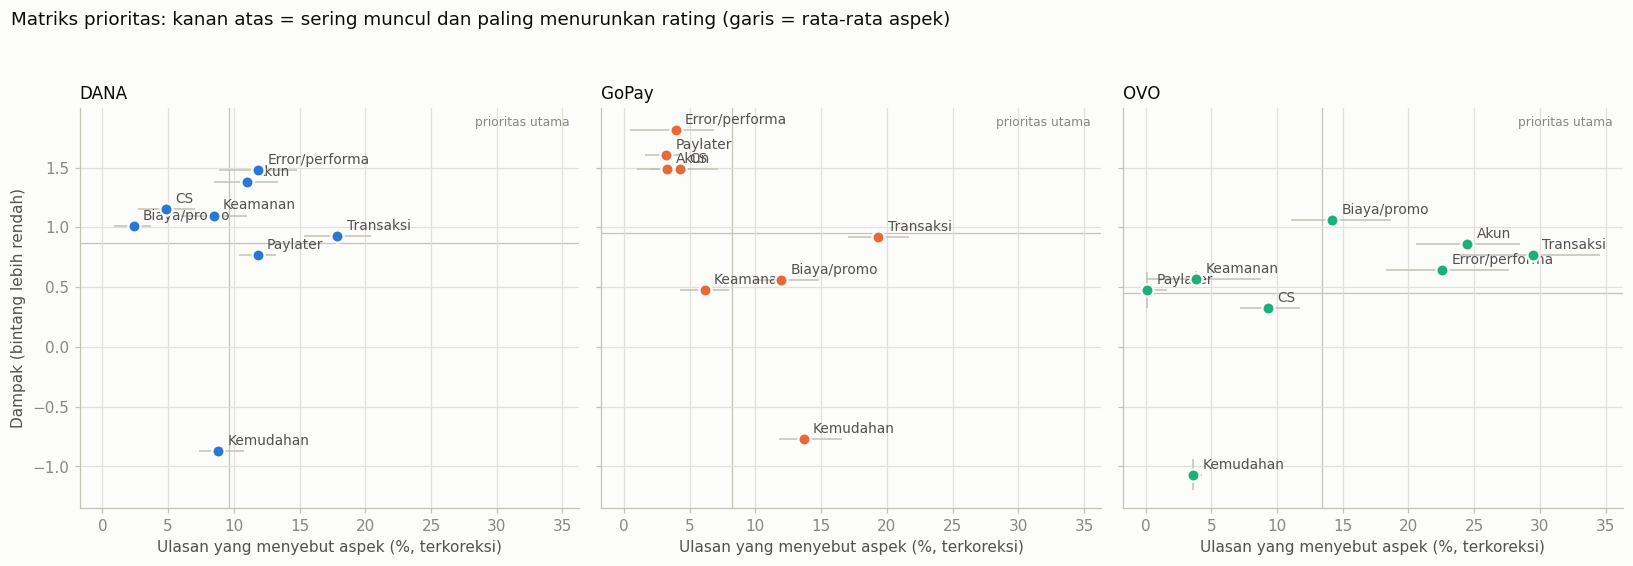

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharex=True, sharey=True)
for ax, nama in zip(axes, URUTAN_APLIKASI):
    m = matriks[matriks['aplikasi'] == nama]
    ax.errorbar(
        m['persen_koreksi'], m['dampak'],
        xerr=[m['persen_koreksi'] - m['persen_bawah'], m['persen_atas'] - m['persen_koreksi']],
        yerr=[m['dampak'] - m['dampak_bawah'], m['dampak_atas'] - m['dampak']],
        fmt='o', color=WARNA[nama], ecolor=GARIS, elinewidth=1, markersize=8,
        markeredgecolor=PERMUKAAN, markeredgewidth=1.5, zorder=3,
    )
    for _, r in m.iterrows():
        ax.annotate(NAMA_ASPEK[r['aspek']], (r['persen_koreksi'], r['dampak']), xytext=(6, 4),
                    textcoords='offset points', fontsize=9, color=TINTA_2)
    ax.axvline(m['persen_koreksi'].mean(), color=GARIS, linewidth=0.8, zorder=1)
    ax.axhline(m['dampak'].mean(), color=GARIS, linewidth=0.8, zorder=1)
    ax.text(0.98, 0.98, 'prioritas utama', transform=ax.transAxes, ha='right', va='top', fontsize=8, color=TINTA_REDUP)
    ax.set_title(NAMA[nama])
    ax.set_xlabel('Ulasan yang menyebut aspek (%, terkoreksi)')
    ax.grid(axis='x', color='#e1e0d9', linewidth=0.8)
axes[0].set_ylabel('Dampak (bintang lebih rendah)')
fig.suptitle('Matriks prioritas: kanan atas = sering muncul dan paling menurunkan rating (garis = rata-rata aspek)',
             x=0.01, ha='left', color=TINTA)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

## 7.5 Perbandingan antar aplikasi per aspek

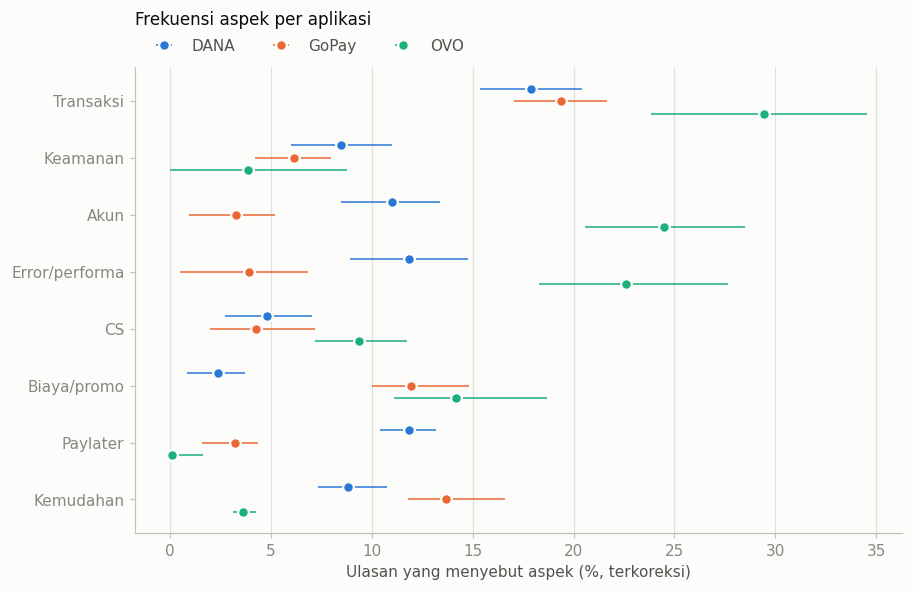

aplikasi,dana,gopay,ovo
aspek,,,
transaksi,17.9,19.4,29.4
keamanan,8.5,6.1,3.9
akun,11.0,3.3,24.5
error_performa,11.9,3.9,22.6
cs,4.8,4.3,9.3
biaya_promo,2.4,11.9,14.2
paylater,11.8,3.2,0.1
kemudahan,8.8,13.7,3.6


In [11]:
fig, ax = plt.subplots(figsize=(9, 5.5))
posisi = np.arange(len(ASPEK))[::-1]
for geser, nama in zip([0.22, 0, -0.22], URUTAN_APLIKASI):
    m = prevalensi[prevalensi['aplikasi'] == nama].set_index('aspek').loc[ASPEK]
    ax.errorbar(
        m['persen_koreksi'], posisi + geser,
        xerr=[m['persen_koreksi'] - m['persen_bawah'], m['persen_atas'] - m['persen_koreksi']],
        fmt='o', color=WARNA[nama], ecolor=WARNA[nama], elinewidth=1, markersize=7,
        markeredgecolor=PERMUKAAN, markeredgewidth=1.5, label=NAMA[nama],
    )
ax.set_yticks(posisi)
ax.set_yticklabels([NAMA_ASPEK[a] for a in ASPEK])
ax.grid(axis='y', visible=False)
ax.grid(axis='x', color='#e1e0d9', linewidth=0.8)
ax.set_xlabel('Ulasan yang menyebut aspek (%, terkoreksi)')
ax.set_title('Frekuensi aspek per aplikasi', pad=28)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3)
plt.show()

display(prevalensi.pivot(index='aspek', columns='aplikasi', values='persen_koreksi').loc[ASPEK, URUTAN_APLIKASI].round(1))

## 7.6 Tren bulanan per aspek

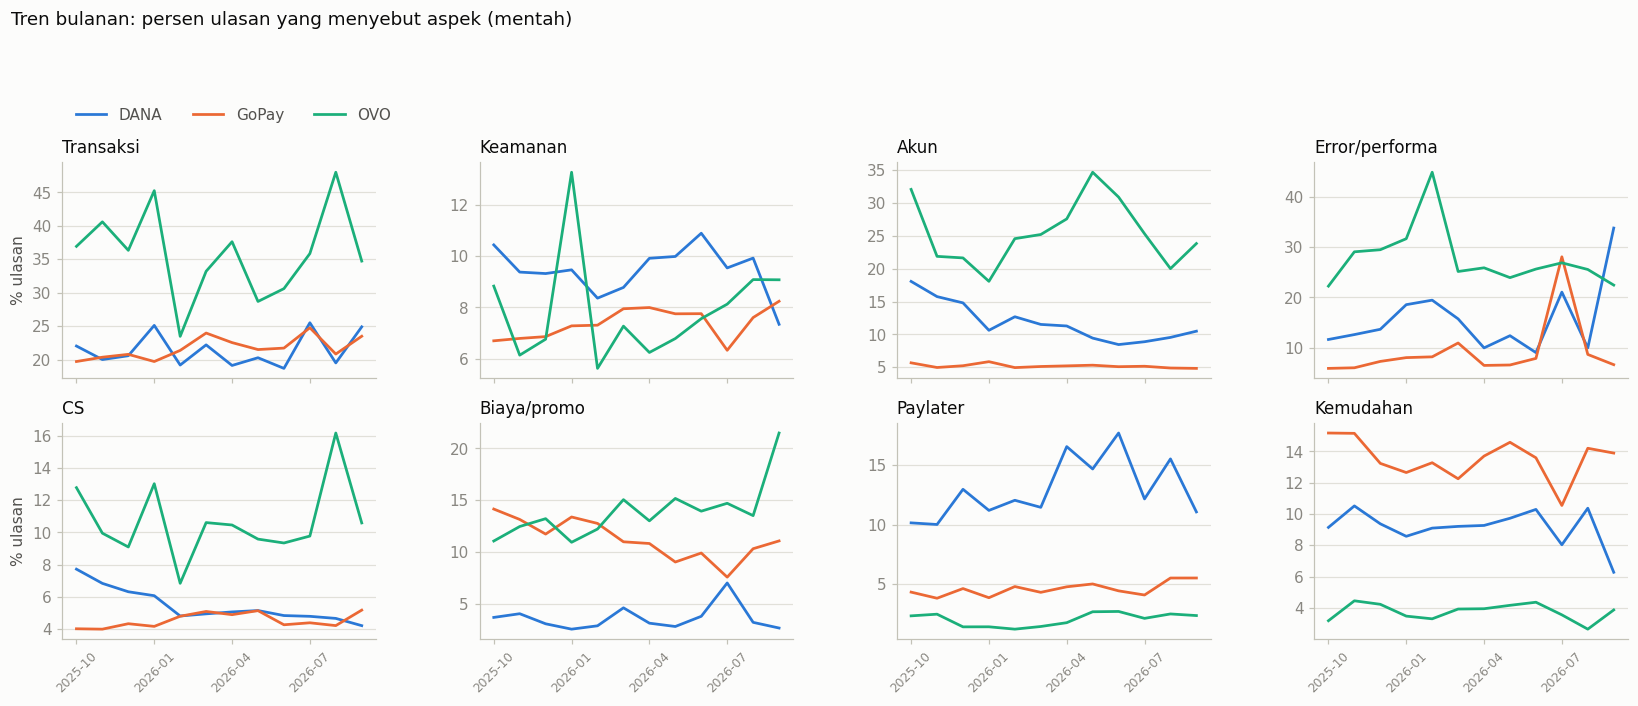

In [12]:
tren = (
    data.groupby(['aplikasi', 'bulan'])
    .agg(jumlah=('id_ulasan', 'size'), persen_negatif=('pred_sentimen', lambda s: (s == 'neg').mean() * 100),
         **{a: (f'pred_{a}', 'mean') for a in ASPEK})
    .reset_index()
)
tren[ASPEK] = tren[ASPEK] * 100
bulan = sorted(tren['bulan'].unique())

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for ax, a in zip(axes.flat, ASPEK):
    for nama in URUTAN_APLIKASI:
        t = tren[tren['aplikasi'] == nama].set_index('bulan').reindex(bulan)
        ax.plot(range(len(bulan)), t[a], color=WARNA[nama], linewidth=1.8, label=NAMA[nama])
    ax.set_title(NAMA_ASPEK[a])
    ax.set_xticks(range(0, len(bulan), 3))
    ax.set_xticklabels([bulan[i] for i in range(0, len(bulan), 3)], rotation=45, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel('% ulasan')
axes[0, 0].legend(loc='lower left', bbox_to_anchor=(0, 1.12), ncol=3)
fig.suptitle('Tren bulanan: persen ulasan yang menyebut aspek (mentah)', x=0.01, ha='left', color=TINTA)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

## 7.7 Lonjakan keluhan per versi

In [13]:
MIN_ULASAN_VERSI, MIN_SELISIH_PP, BATAS_Q = 200, 5, 0.05


def kunci_versi(v):
    return tuple(int(x) for x in re.findall(r'\d+', v))


def uji_versi(d):
    d = d[d['versi'].fillna('') != '']
    jumlah = d['versi'].value_counts()
    baris = []
    for v in jumlah[jumlah >= MIN_ULASAN_VERSI].index:
        di_versi = (d['versi'] == v).to_numpy()
        n1, n0 = di_versi.sum(), (~di_versi).sum()
        for a in ASPEK:
            nilai = d[f'pred_{a}'].to_numpy()
            x1, x0 = nilai[di_versi].sum(), nilai[~di_versi].sum()
            p = proportions_ztest([x1, x0], [n1, n0], alternative='larger')[1] if x1 + x0 > 0 else 1.0
            baris.append({'versi': v, 'aspek': a, 'n_versi': n1, 'persen_versi': x1 / n1 * 100,
                          'persen_lain': x0 / n0 * 100, 'p': p})
    hasil = pd.DataFrame(baris)
    hasil['q'] = multipletests(hasil['p'].fillna(1.0), method='fdr_bh')[1]
    hasil['selisih_pp'] = hasil['persen_versi'] - hasil['persen_lain']
    hasil['lonjakan'] = (hasil['q'] < BATAS_Q) & (hasil['selisih_pp'] >= MIN_SELISIH_PP)
    return hasil


bagian = []
for nama in URUTAN_APLIKASI:
    d = data[data['aplikasi'] == nama]
    semua = uji_versi(d)
    tanpa = uji_versi(d[~d['hari_lonjakan']])[['versi', 'aspek', 'selisih_pp', 'lonjakan']]
    pertama = d.groupby('versi')['tanggal'].min().rename('pertama_muncul')
    gabung = (semua.merge(tanpa, on=['versi', 'aspek'], how='left', suffixes=('', '_tanpa_lonjakan'))
              .merge(pertama, left_on='versi', right_index=True).assign(aplikasi=nama))
    bagian.append(gabung)
    print(f'{NAMA[nama]}: {gabung["versi"].nunique()} versi diuji, {len(gabung)} uji, '
          f'{int(gabung["lonjakan"].sum())} lonjakan')
lonjakan_versi = pd.concat(bagian, ignore_index=True)

kolom = ['versi', 'pertama_muncul', 'aspek', 'n_versi', 'persen_versi', 'persen_lain', 'selisih_pp', 'q',
         'selisih_pp_tanpa_lonjakan', 'lonjakan_tanpa_lonjakan']
for nama in URUTAN_APLIKASI:
    t = lonjakan_versi[(lonjakan_versi['aplikasi'] == nama) & lonjakan_versi['lonjakan']]
    print(f'\n{NAMA[nama]}: lonjakan terbesar (lonjakan_tanpa_lonjakan = True berarti bertahan tanpa hari insiden)')
    display(t.sort_values('selisih_pp', ascending=False).head(12)[kolom].round(3))

DANA: 66 versi diuji, 528 uji, 20 lonjakan
GoPay: 31 versi diuji, 248 uji, 4 lonjakan
OVO: 25 versi diuji, 200 uji, 18 lonjakan

DANA: lonjakan terbesar (lonjakan_tanpa_lonjakan = True berarti bertahan tanpa hari insiden)


,versi,pertama_muncul,aspek,n_versi,persen_versi,persen_lain,selisih_pp,q,selisih_pp_tanpa_lonjakan,lonjakan_tanpa_lonjakan
27,2.145.0,2026-09-19 16:38:09,error_performa,9438,56.315,13.909,42.406,0.000,3.836,False
35,2.134.0,2026-07-11 00:09:19,error_performa,6728,32.922,15.343,17.579,0.000,1.215,False
80,2.110.0,2026-01-10 23:14:40,transaksi,5027,37.756,21.328,16.428,0.000,8.113,True
83,2.110.0,2026-01-10 23:14:40,error_performa,5027,29.918,15.578,14.340,0.000,0.445,False
318,2.131.1,2026-06-23 18:49:40,paylater,1737,25.619,12.709,12.910,0.000,12.540,True
32,2.134.0,2026-07-11 00:09:19,transaksi,6728,31.703,21.395,10.308,0.000,-1.175,False
24,2.145.0,2026-09-19 16:38:09,transaksi,9438,31.257,21.269,9.988,0.000,0.526,False
230,2.122.0,2026-04-17 13:02:58,paylater,2659,21.813,12.699,9.113,0.000,8.266,True
322,2.105.1,2025-11-27 22:33:14,akun,1662,19.134,10.700,8.434,0.000,8.252,True
434,2.100.0,2025-10-04 00:07:36,akun,335,17.910,10.759,7.152,0.000,7.042,True



GoPay: lonjakan terbesar (lonjakan_tanpa_lonjakan = True berarti bertahan tanpa hari insiden)


,versi,pertama_muncul,aspek,n_versi,persen_versi,persen_lain,selisih_pp,q,selisih_pp_tanpa_lonjakan,lonjakan_tanpa_lonjakan
587,2.14.1,2026-07-11 17:31:26,error_performa,4474,30.219,8.199,22.020,0.000,0.971,False
555,2.15.0,2026-07-22 16:40:42,error_performa,5852,27.597,8.057,19.541,0.000,4.598,False
728,2.19.1,2026-09-18 08:30:28,transaksi,679,27.541,21.228,6.313,0.001,6.670,True
749,1.57.0,2025-10-01 02:28:59,biaya_promo,461,16.920,10.886,6.034,0.000,5.921,True



OVO: lonjakan terbesar (lonjakan_tanpa_lonjakan = True berarti bertahan tanpa hari insiden)


,versi,pertama_muncul,aspek,n_versi,persen_versi,persen_lain,selisih_pp,q,selisih_pp_tanpa_lonjakan,lonjakan_tanpa_lonjakan
803,3.153.0,2026-01-28 23:55:53,error_performa,952,47.479,27.459,20.020,0.000,20.226,True
808,3.166.0,2026-07-28 16:33:07,transaksi,798,56.892,37.329,19.563,0.000,15.486,True
824,3.146.0,2025-10-24 14:29:38,transaksi,645,50.233,37.784,12.448,0.000,13.475,True
963,3.154.0,2026-02-11 19:42:16,error_performa,310,40.645,28.375,12.270,0.000,12.352,True
786,3.144.0,2025-10-01 00:33:48,akun,1199,34.362,23.132,11.230,0.000,0.871,False
968,3.158.0,2026-04-10 10:34:50,transaksi,304,47.697,38.091,9.606,0.003,-2.267,False
946,3.160.0,2026-05-11 08:38:52,akun,375,32.000,23.755,8.245,0.001,8.402,True
776,3.150.0,2025-12-18 16:31:20,transaksi,1756,45.615,37.400,8.215,0.000,4.746,False
827,3.146.0,2025-10-24 14:29:38,error_performa,645,36.279,28.295,7.984,0.000,8.133,True
914,3.161.0,2026-05-20 13:12:11,akun,474,31.646,23.715,7.931,0.000,8.091,True


## 7.8 Apa yang terjadi di hari insiden

In [14]:
data['hari'] = data['tanggal'].dt.normalize()
normal = data[~data['hari_lonjakan']].groupby('aplikasi')[KOLOM_PRED].mean() * 100
negatif_normal = data[~data['hari_lonjakan']].groupby('aplikasi')['pred_sentimen'].apply(lambda s: (s == 'neg').mean() * 100)

baris = []
for (nama, hari), d in data[data['hari_lonjakan']].groupby(['aplikasi', 'hari']):
    persen = d[KOLOM_PRED].mean() * 100
    naik = (persen - normal.loc[nama]).set_axis(ASPEK).sort_values(ascending=False)
    baris.append({
        'aplikasi': nama, 'hari': hari, 'jumlah': len(d),
        'persen_negatif': (d['pred_sentimen'] == 'neg').mean() * 100,
        'persen_negatif_normal': negatif_normal.loc[nama],
        'aspek_teratas': '; '.join(f"{NAMA_ASPEK[a]} {persen[f'pred_{a}']:.0f}% (+{naik[a]:.0f} pp)"
                                   for a in naik.index[:3]),
        **{a: persen[f'pred_{a}'] for a in ASPEK},
    })
insiden = pd.DataFrame(baris)
with pd.option_context('display.max_colwidth', 120):
    display(insiden[['aplikasi', 'hari', 'jumlah', 'persen_negatif', 'persen_negatif_normal', 'aspek_teratas']].round(1))

,aplikasi,hari,jumlah,persen_negatif,persen_negatif_normal,aspek_teratas
0,dana,2026-01-18,3852,86.1,44.7,Error/performa 47% (+34 pp); Transaksi 47% (+27 pp); CS 7% (+2 pp)
1,dana,2026-07-20,4899,90.1,44.7,Error/performa 55% (+42 pp); Transaksi 45% (+25 pp); Biaya/promo 15% (+12 pp)
2,dana,2026-09-25,10793,93.6,44.7,Error/performa 70% (+57 pp); Transaksi 34% (+14 pp); Akun 12% (+-0 pp)
3,gopay,2026-07-28,4021,91.3,29.3,Error/performa 79% (+71 pp); Transaksi 34% (+12 pp); CS 3% (+-1 pp)
4,ovo,2025-10-06,302,96.7,85.5,Akun 69% (+44 pp); Keamanan 21% (+13 pp); Error/performa 28% (+0 pp)
5,ovo,2025-10-07,252,93.3,85.5,Akun 41% (+16 pp); CS 20% (+10 pp); Transaksi 43% (+7 pp)
6,ovo,2026-01-11,430,95.8,85.5,Transaksi 66% (+31 pp); Keamanan 27% (+20 pp); Error/performa 32% (+4 pp)
7,ovo,2026-04-19,176,96.0,85.5,Transaksi 68% (+33 pp); CS 19% (+9 pp); Error/performa 32% (+5 pp)
8,ovo,2026-08-08,262,97.3,85.5,Transaksi 75% (+39 pp); CS 23% (+12 pp); Keamanan 8% (+0 pp)


## 7.9 Respons developer

In [15]:
data['dibalas'] = data['balasan'].notna()
data['jam_balasan'] = (data['tanggal_balasan'] - data['tanggal']).dt.total_seconds() / 3600
data['balasan_valid'] = data['dibalas'] & (data['jam_balasan'] >= 0)
isi_negatif = data['pred_sentimen'] == 'neg'


def persen_dibalas(mask):
    return data[mask].groupby('aplikasi')['dibalas'].mean() * 100


respons = pd.DataFrame({
    'persen_dibalas_semua': persen_dibalas(data['rating'] > 0),
    'persen_dibalas_bintang_1_2_isi_negatif': persen_dibalas((data['rating'] <= 2) & isi_negatif),
    'persen_dibalas_bintang_4_5_isi_negatif': persen_dibalas((data['rating'] >= 4) & isi_negatif),
    'persen_dibalas_bintang_4_5_isi_positif': persen_dibalas((data['rating'] >= 4) & (data['pred_sentimen'] == 'pos')),
    'persen_balasan_valid': data[data['dibalas']].groupby('aplikasi')['balasan_valid'].mean() * 100,
    'median_jam_balasan': data[data['balasan_valid']].groupby('aplikasi')['jam_balasan'].median(),
    'p90_jam_balasan': data[data['balasan_valid']].groupby('aplikasi')['jam_balasan'].quantile(0.9),
    'jumlah_balasan_valid': data[data['balasan_valid']].groupby('aplikasi').size(),
}).round(1)
display(respons)

print('Persen ulasan berisi keluhan (menurut model) yang dibalas, per aspek:')
respons_aspek = pd.DataFrame({
    a: data[isi_negatif & (data[f'pred_{a}'] == 1)].groupby('aplikasi')['dibalas'].mean() * 100 for a in ASPEK
}).T.round(1)
display(respons_aspek[URUTAN_APLIKASI])

,persen_dibalas_semua,persen_dibalas_bintang_1_2_isi_negatif,persen_dibalas_bintang_4_5_isi_negatif,persen_dibalas_bintang_4_5_isi_positif,persen_balasan_valid,median_jam_balasan,p90_jam_balasan,jumlah_balasan_valid
aplikasi,,,,,,,,
dana,36.6,75.8,42.3,1.2,95.1,1.5,9.1,83470.0
gopay,21.9,87.0,4.1,0.2,93.5,1.3,153.8,27775.0
ovo,1.7,1.7,3.0,0.6,0.0,NaN,NaN,NaN


Persen ulasan berisi keluhan (menurut model) yang dibalas, per aspek:


aplikasi,dana,gopay,ovo
transaksi,65.9,81.4,2.2
keamanan,80.5,77.8,2.2
akun,79.6,72.9,1.8
error_performa,56.6,74.8,2.1
cs,83.4,88.5,2.1
biaya_promo,67.6,59.2,2.0
paylater,68.2,70.7,2.0
kemudahan,61.8,35.8,1.0


## 7.10 Simpan data agregat untuk dashboard

In [16]:
simpan = {
    'matriks_prioritas': matriks,
    'sentimen_vs_rating': sentimen_vs_rating.reset_index(),
    'ringkas_rating': ringkas_rating.rename_axis('aplikasi').reset_index(),
    'tren_bulanan': tren,
    'lonjakan_versi': lonjakan_versi[lonjakan_versi['lonjakan'] | lonjakan_versi['lonjakan_tanpa_lonjakan'].fillna(False)],
    'insiden': insiden,
    'respons_developer': respons.rename_axis('aplikasi').reset_index(),
    'respons_per_aspek': respons_aspek.rename_axis('aspek').reset_index(),
}
for nama_file, tabel in simpan.items():
    path = FOLDER_APP_DATA / f'{nama_file}.parquet'
    tabel.to_parquet(path, index=False)
    print(f'{nama_file}.parquet: {len(tabel)} baris, {path.stat().st_size / 1024:.0f} KB')
_ = (FOLDER_APP_DATA / 'info.json').write_text(json.dumps(
    {**info_prediksi, 'jumlah_ulasan': len(data), 'periode': f"{data['bulan'].min()} s.d. {data['bulan'].max()}"},
    indent=2, ensure_ascii=False), encoding='utf-8')

matriks_prioritas.parquet: 24 baris, 10 KB
sentimen_vs_rating.parquet: 9 baris, 4 KB
ringkas_rating.parquet: 3 baris, 4 KB
tren_bulanan.parquet: 36 baris, 10 KB
lonjakan_versi.parquet: 51 baris, 11 KB
insiden.parquet: 9 baris, 10 KB
respons_developer.parquet: 3 baris, 7 KB
respons_per_aspek.parquet: 8 baris, 3 KB


/tmp/ipykernel_477/1933265458.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  'lonjakan_versi': lonjakan_versi[lonjakan_versi['lonjakan'] | lonjakan_versi['lonjakan_tanpa_lonjakan'].fillna(False)],


174

## 7.11 Bahan dashboard

In [17]:
import shutil
import sys
from importlib.metadata import metadata, version

from sklearn.metrics import f1_score

FOLDER_APP = FOLDER_PROJECT / 'app'
for nama_folder in ['models', 'kamus']:
    (FOLDER_APP / nama_folder).mkdir(parents=True, exist_ok=True)

# 1. Model TF-IDF (demo live) dan kamus praproses
for nama_file in ['tfidf_sentimen_gold.joblib', 'tfidf_aspek.joblib']:
    shutil.copy2(FOLDER_MODEL / nama_file, FOLDER_APP / 'models' / nama_file)
for nama_file in ['slang_final.csv', 'stopword.txt']:
    shutil.copy2(FOLDER_PROJECT / 'kamus' / nama_file, FOLDER_APP / 'kamus' / nama_file)

# 2. Skor semua model di dev (lipatan dan bootstrap sama dengan 03 dan 04)
gold_train = pd.read_parquet(FOLDER_GOLD / 'gold_train.parquet')
dev = gold_train[gold_train['sumber'] != 'tambahan'].reset_index(drop=True)
y_dev, Y_dev = dev['sentimen'].to_numpy(), dev[ASPEK].to_numpy()


def interval_bootstrap(y_true, y_pred, fungsi, n=1000):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    indeks = np.random.default_rng(SEED).integers(0, len(y_true), size=(n, len(y_true)))
    return np.percentile([fungsi(y_true[i], y_pred[i]) for i in indeks], [2.5, 97.5])


def macro_f1(y, p):
    return f1_score(y, p, labels=KELAS, average='macro', zero_division=0)


def macro_f1_aspek(y, p):
    return f1_score(y, p, average='macro', zero_division=0)


file_indobert = {
    'IndoBERT, label gold': f'oof_sentimen_gold_IndoBERT_{VERSI_LABEL}.npy',
    'IndoBERTweet, label gold': f'oof_sentimen_gold_IndoBERTweet_{VERSI_LABEL}.npy',
    'IndoBERT, label rating': 'dev_sentimen_rating.npy',
    'Dua tahap (rating -> gold)': f'oof_sentimen_dua_tahap_{VERSI_LABEL}.npy',
}
baris = []
for nama, nama_file in file_indobert.items():
    pred = np.array(KELAS)[np.load(FOLDER_HASIL_INDOBERT / nama_file).argmax(axis=1)]
    bawah, atas = interval_bootstrap(y_dev, pred, macro_f1)
    f1_kelas = f1_score(y_dev, pred, labels=KELAS, average=None, zero_division=0)
    baris.append({'kelompok': 'IndoBERT', 'model': nama, 'macro_f1': round(macro_f1(y_dev, pred), 3),
                  'ci_95': f'{bawah:.2f}-{atas:.2f}', **{f'f1_{k}': round(v, 3) for k, v in zip(KELAS, f1_kelas)}})

baseline_sentimen = pd.read_parquet(FOLDER_PROCESSED / 'ringkasan_dev_baseline_sentimen.parquet')
baseline_aspek = pd.read_parquet(FOLDER_PROCESSED / 'ringkasan_dev_baseline_aspek.parquet')
assert (baseline_sentimen['versi_label'] == VERSI_LABEL).all() and (baseline_aspek['versi_label'] == VERSI_LABEL).all(), \
    'Ringkasan baseline dari versi label lain; jalankan ulang 03_baseline.ipynb'
model_dev_sentimen = pd.concat([baseline_sentimen.assign(kelompok='baseline'), pd.DataFrame(baris)], ignore_index=True)[
    ['kelompok', 'model', 'macro_f1', 'ci_95', 'f1_neg', 'f1_net', 'f1_pos']
]

path_oof_aspek = sorted(FOLDER_HASIL_INDOBERT.glob(f'oof_aspek_*_{VERSI_LABEL}.npy'))
assert len(path_oof_aspek) == 1, path_oof_aspek
pred_aspek = (np.load(path_oof_aspek[0]) >= info_aspek['ambang']).astype(int)
bawah, atas = interval_bootstrap(Y_dev, pred_aspek, macro_f1_aspek)
f1_aspek = f1_score(Y_dev, pred_aspek, average=None, zero_division=0)
model_dev_aspek = pd.concat([
    baseline_aspek.drop(columns='versi_label'),
    pd.DataFrame([{'model': info_aspek['nama'], 'macro_f1': round(macro_f1_aspek(Y_dev, pred_aspek), 3),
                   'ci_95': f'{bawah:.2f}-{atas:.2f}', **{f'f1_{a}': round(v, 3) for a, v in zip(ASPEK, f1_aspek)}}]),
], ignore_index=True)

model_dev_sentimen.to_parquet(FOLDER_APP_DATA / 'model_dev_sentimen.parquet', index=False)
model_dev_aspek.to_parquet(FOLDER_APP_DATA / 'model_dev_aspek.parquet', index=False)
display(model_dev_sentimen)
display(model_dev_aspek)

# 3. requirements.txt: scikit-learn harus sama dengan versi yang dipakai saat model dilatih
v_sklearn, v_numpy = version('scikit-learn'), version('numpy')
mayor_numpy = int(v_numpy.split('.')[0])
(FOLDER_APP / 'requirements.txt').write_text('\n'.join([
    '# Dibuat otomatis oleh 05_insight.ipynb (7.11). scikit-learn harus sama dengan saat model TF-IDF dilatih.',
    'streamlit==1.40.2',
    'plotly==5.24.1',
    'pandas>=2.0,<3',
    'pyarrow>=14',
    f'numpy>={mayor_numpy}.0,<{mayor_numpy + 1}',
    f'scikit-learn=={v_sklearn}',
    'joblib>=1.3',
]) + '\n', encoding='utf-8')
print(f'scikit-learn {v_sklearn} (butuh Python {metadata("scikit-learn")["Requires-Python"]}), numpy {v_numpy}, '
      f'Python Colab {sys.version.split()[0]}')

print('\nIsi folder app/ di Drive:')
for path in sorted(FOLDER_APP.rglob('*')):
    if path.is_file():
        print(f'  {path.relative_to(FOLDER_APP)}  ({path.stat().st_size / 1024:,.0f} KB)')

,kelompok,model,macro_f1,ci_95,f1_neg,f1_net,f1_pos
0,baseline,Rating bintang,0.523,0.49-0.55,0.709,0.174,0.685
1,baseline,Panjang ulasan saja,0.534,0.50-0.57,0.780,0.144,0.679
2,baseline,Lexicon InSet,0.467,0.43-0.51,0.801,0.183,0.418
3,baseline,"TF-IDF + LR, label rating (C=1)",0.599,0.57-0.63,0.798,0.179,0.820
4,baseline,"TF-IDF + LR, label gold (C=1)",0.817,0.77-0.85,0.936,0.603,0.912
5,IndoBERT,"IndoBERT, label gold",0.859,0.82-0.89,0.958,0.655,0.964
6,IndoBERT,"IndoBERTweet, label gold",0.831,0.79-0.87,0.951,0.612,0.930
7,IndoBERT,"IndoBERT, label rating",0.558,0.53-0.59,0.679,0.157,0.840
8,IndoBERT,Dua tahap (rating -> gold),0.868,0.83-0.90,0.958,0.678,0.969


,model,macro_f1,ci_95,f1_transaksi,f1_keamanan,f1_akun,f1_error_performa,f1_cs,f1_biaya_promo,f1_paylater,f1_kemudahan
0,Kata kunci,0.737,0.70-0.76,0.660,0.627,0.800,0.776,0.742,0.765,0.886,0.636
1,TF-IDF + OvR LR (C=16),0.770,0.74-0.80,0.780,0.659,0.814,0.807,0.788,0.843,0.875,0.590
2,IndoBERT multi-label,0.797,0.77-0.82,0.817,0.655,0.833,0.823,0.754,0.807,0.876,0.809


scikit-learn 1.6.1 (butuh Python >=3.9), numpy 2.1.3, Python Colab 3.13.15

Isi folder app/ di Drive:
  data/info.json  (0 KB)
  data/insiden.parquet  (10 KB)
  data/lonjakan_versi.parquet  (11 KB)
  data/matriks_prioritas.parquet  (10 KB)
  data/model_dev_aspek.parquet  (7 KB)
  data/model_dev_sentimen.parquet  (5 KB)
  data/respons_developer.parquet  (7 KB)
  data/respons_per_aspek.parquet  (3 KB)
  data/ringkas_rating.parquet  (4 KB)
  data/sentimen_vs_rating.parquet  (4 KB)
  data/tren_bulanan.parquet  (10 KB)
  kamus/slang_final.csv  (63 KB)
  kamus/stopword.txt  (1 KB)
  models/tfidf_aspek.joblib  (941 KB)
  models/tfidf_sentimen_gold.joblib  (560 KB)
  requirements.txt  (0 KB)


## 7.12 Data jelajah untuk dashboard

In [8]:
import re
from collections import Counter

d = data.merge(
    pd.read_parquet(FOLDER_PROCESSED / 'ulasan_bersih.parquet', columns=['id_ulasan', 'teks', 'teks_penuh']),
    on='id_ulasan',
)
d['hari'] = d['tanggal'].dt.normalize()
d['negatif'] = d['pred_sentimen'].eq('neg')

# a. Kubus: aplikasi x bulan x bintang x sentimen x hari insiden, dengan jumlah ulasan per aspek
kubus = (
    d.groupby(['aplikasi', 'bulan', 'rating', 'pred_sentimen', 'hari_lonjakan'])
    .agg(jumlah=('id_ulasan', 'size'), **{a: (f'pred_{a}', 'sum') for a in ASPEK})
    .reset_index().rename(columns={'pred_sentimen': 'sentimen'})
)

# b. Volume harian per bintang
harian = (
    d.groupby(['aplikasi', 'hari', 'rating'])
    .agg(jumlah=('id_ulasan', 'size'), negatif=('negatif', 'sum'), hari_lonjakan=('hari_lonjakan', 'max'))
    .reset_index()
)

# c. Per versi (>= 200 ulasan)
versi = (
    d[d['versi'].fillna('') != ''].groupby(['aplikasi', 'versi'])
    .agg(jumlah=('id_ulasan', 'size'), rating_rata2=('rating', 'mean'), persen_keluhan=('negatif', 'mean'),
         pertama_muncul=('tanggal', 'min'), **{a: (f'pred_{a}', 'mean') for a in ASPEK})
    .reset_index()
)
versi = versi[versi['jumlah'] >= 200].copy()
versi[['persen_keluhan'] + ASPEK] *= 100

# d. Kata khas keluhan tiap aspek: weighted log-odds (Monroe dkk., 2008), keluhan aspek ini vs keluhan lain di aplikasi yang sama
KATA_UMUM = {'dana', 'gopay', 'ovo', 'aplikasi', 'tidak', 'bisa', 'sudah', 'nya', 'saya'}


def hitung_ngram(daftar_teks):
    hitung = Counter()
    for t in daftar_teks:
        kata = t.split()
        hitung.update(w for w in kata if w not in KATA_UMUM)
        hitung.update(' '.join(p) for p in zip(kata, kata[1:]))
    return hitung


def log_odds(hitung_a, hitung_b, min_frek=20):
    latar = hitung_a + hitung_b
    n_a, n_b, alpha0 = sum(hitung_a.values()), sum(hitung_b.values()), sum(latar.values())
    hasil = []
    for w, alpha in latar.items():
        if alpha < min_frek:
            continue
        ya, yb = hitung_a.get(w, 0), hitung_b.get(w, 0)
        delta = (np.log((ya + alpha) / (n_a + alpha0 - ya - alpha)) - np.log((yb + alpha) / (n_b + alpha0 - yb - alpha)))
        hasil.append((w, ya, delta / np.sqrt(1 / (ya + alpha) + 1 / (yb + alpha))))
    return pd.DataFrame(hasil, columns=['ngram', 'frekuensi', 'z']).sort_values('z', ascending=False)


baris = []
for nama in URUTAN_APLIKASI:
    keluhan = d[(d['aplikasi'] == nama) & d['negatif']]
    total = hitung_ngram(keluhan['teks_penuh'])
    for a in ASPEK:
        bagian = keluhan[keluhan[f'pred_{a}'] == 1]
        if len(bagian) < 50:
            continue
        hitung_a = hitung_ngram(bagian['teks_penuh'])
        hitung_b = total.copy()
        hitung_b.subtract(hitung_a)
        hitung_b = +hitung_b  # buang hitungan <= 0
        teratas = log_odds(hitung_a, hitung_b).head(12)
        baris += [{'aplikasi': nama, 'aspek': a, 'ngram': w, 'frekuensi': int(f), 'z': z}
                  for w, f, z in teratas[['ngram', 'frekuensi', 'z']].values]
kata_keluhan = pd.DataFrame(baris)

# e. Contoh ulasan yang sudah disaring dan disamarkan
KATA_KASAR = (r'\b(?:anjing|anjg|anj|ajg|anjir|asu|babi|bangsat|bgst|bajingan|kontol|kntl|memek|ngentot|ngentod|jancok'
              r'|jancuk|goblok|goblog|gblk|tolol|bego|idiot|tai|taik|sialan|kampret|brengsek|setan|bodoh|keparat'
              r'|dongo|bacot|kampang|tolil)\b')
d['teks_satu_baris'] = d['teks'].str.replace(r'\s+', ' ', regex=True).str.strip()
kandidat = d[
    d['jumlah_kata'].between(6, 40)
    & ~d['teks_satu_baris'].str.contains(r'@|https?://|www\.|\d{4,}', regex=True)
    & ~d['teks_satu_baris'].str.lower().str.contains(KATA_KASAR, regex=True)
    & ~d['teks_ringan'].str.contains(KATA_KASAR, regex=True)
]
contoh = []
for nama in URUTAN_APLIKASI:
    for a in ASPEK:
        for sentimen in ['neg', 'pos']:
            pool = kandidat[(kandidat['aplikasi'] == nama) & (kandidat[f'prob_{a}'] >= 0.8)
                            & (kandidat[f'prob_{sentimen}'] >= 0.8)]
            for r in pool.sample(n=min(3, len(pool)), random_state=SEED).itertuples():
                contoh.append({'aplikasi': nama, 'aspek': a, 'sentimen': sentimen, 'rating': r.rating,
                               'bulan': r.bulan, 'teks': re.sub(r'\d{6,}', '<angka>', r.teks_satu_baris)})
contoh_ulasan = pd.DataFrame(contoh)

for nama_file, tabel in {'kubus': kubus, 'harian': harian, 'versi': versi,
                         'kata_keluhan': kata_keluhan, 'contoh_ulasan': contoh_ulasan}.items():
    path = FOLDER_APP_DATA / f'{nama_file}.parquet'
    tabel.to_parquet(path, index=False)
    print(f'{nama_file}.parquet: {len(tabel):,} baris, {path.stat().st_size / 1024:,.0f} KB')

print('\nContoh ulasan per aplikasi x sentimen:')
display(contoh_ulasan.groupby(['aplikasi', 'sentimen']).size().unstack())
print('Kata khas keluhan (3 teratas per aplikasi x aspek):')
display(kata_keluhan.groupby(['aplikasi', 'aspek']).head(3).groupby(['aplikasi', 'aspek'])['ngram'].apply(', '.join).unstack(0))

kubus.parquet: 625 baris, 20 KB
harian.parquet: 5,358 baris, 25 KB
versi.parquet: 122 baris, 21 KB
kata_keluhan.parquet: 288 baris, 9 KB
contoh_ulasan.parquet: 144 baris, 14 KB

Contoh ulasan per aplikasi x sentimen:


sentimen,neg,pos
aplikasi,,
dana,24,24
gopay,24,24
ovo,24,24


Kata khas keluhan (3 teratas per aplikasi x aspek):


aplikasi,dana,gopay,ovo
aspek,,,
akun,"login, akun, nomor","akun, login, upgrade","login, nomor, akun"
biaya_promo,"event, poin, hadiah","promo, cashback, voucher","admin, biaya, potongan"
cs,"cs, chat, respon","cs, respon, chat","cs, respon, bantuan"
error_performa,"error, gangguan, buka","gangguan, error, teknis","error, update, gangguan"
keamanan,"hilang, aman, tiba","hilang, aman, tiba","hilang, tiba, aman"
kemudahan,"mudah, gampang, ribet","mudah, fitur, ribet","ribet, mudah, gampang"
paylater,"cicil, dana cicil, cicil tidak","pinjam, pinjaman, gopay pinjam","paylater, pinjaman, ovo paylater"
transaksi,"transaksi, transfer, saldo","topup, masuk, transfer","saldo, transfer, tidak masuk"


### Temuan utama Fase 7